In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import chi2_contingency
from scipy.stats.contingency import association

%matplotlib inline

In [2]:
df = pd.read_csv("../amz_uk_price_prediction_dataset.csv")
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


### Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

1. **Crosstab Analysis**:
    
    - Create a crosstab between the product `category` and the `isBestSeller` status.
        
    - Are there categories where being a best-seller is more prevalent?
        
        _Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order._
        
2. **Statistical Tests**:
    
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.
3. **Visualizations**:
    
    - Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

In [18]:
cat_best_seller = pd.crosstab(df["category"], df["isBestSeller"])

In [20]:
cat_best_seller["proportion"] = cat_best_seller[True]/(cat_best_seller[True] + cat_best_seller[False]) * 100

In [21]:
cat_best_seller.sort_values("proportion", ascending = False)
#grocery, smart home security & lighting and health & perosnal care

isBestSeller,False,True,proportion
category,,,
Grocery,9008,556,5.813467
Smart Home Security & Lighting,98,6,5.769231
Health & Personal Care,9017,552,5.768628
Mobile Phone Accessories,248,11,4.247104
Power & Hand Tools,8353,306,3.533895
...,...,...,...
"CD, Disc & Tape Players",8798,0,0.000000
General Music-Making Accessories,259,0,0.000000
Snowboard Boots,1449,0,0.000000


In [41]:
pd.crosstab(df["category"], df["isBestSeller"])

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [39]:
chi2_contingency(pd.crosstab(df["category"], df["isBestSeller"]))

Chi2ContingencyResult(statistic=np.float64(36540.20270061387), pvalue=np.float64(0.0), dof=295, expected_freq=array([[2.47190130e+02, 8.09870149e-01],
       [4.05371878e+03, 1.32812173e+01],
       [2.49183599e+02, 8.16401360e-01],
       [1.69145827e+03, 5.54173243e+00],
       [2.53170536e+02, 8.29463782e-01],
       [8.50214439e+03, 2.78556144e+01],
       [1.06650580e+02, 3.49419782e-01],
       [2.57157474e+02, 8.42526204e-01],
       [9.51781673e+03, 3.11832664e+01],
       [1.50008526e+04, 4.91473619e+01],
       [9.32544700e+03, 3.05530045e+01],
       [2.38219520e+02, 7.80479700e-01],
       [3.22941944e+03, 1.05805616e+01],
       [9.44704859e+03, 3.09514084e+01],
       [6.68808779e+03, 2.19122125e+01],
       [5.26275760e+02, 1.72423967e+00],
       [1.90296531e+04, 6.23469391e+01],
       [2.77191835e+03, 9.08164873e+00],
       [2.53170536e+02, 8.29463782e-01],
       [4.04674164e+02, 1.32583581e+00],
       [1.92489346e+04, 6.30653723e+01],
       [3.10482764e+03, 1.017

In [23]:
chi2_contingency(cat_best_seller)[1]
#this is the p-value. It is less than 0.05 so it's indicating there is a relationship between variables.

np.float64(0.0)

In [28]:
association(pd.crosstab(df["category"], df["isBestSeller"]), method = "cramer")
# it wasn't working with the variable, I don't get why.
# this suggests a weak association between this variables

0.1222829439760564

<Axes: xlabel='category'>

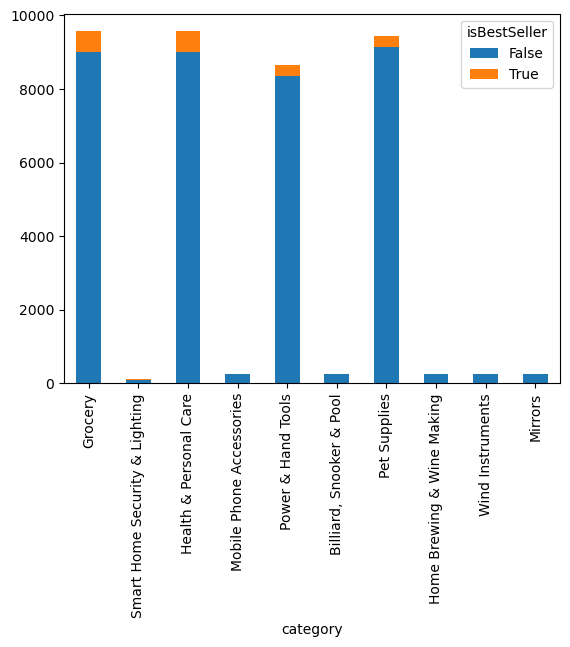

In [47]:
cat_best_seller.sort_values("proportion", ascending = False).drop(columns = ["proportion"]).head(10).plot(kind = "bar", stacked = True)

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

0. **Preliminary Step: Remove outliers in product prices.**
    
    For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
    
    _Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this._
    
1. **Violin Plots**:
    
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.
2. **Bar Charts**:
    
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.
3. **Box Plots**:
    
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [49]:
def tukeys_test_outliers(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = data[(data < lower_bound) | (data > upper_bound)]
    
    return outliers

In [52]:
outliers_for_price = tukeys_test_outliers(df["price"])

In [60]:
df_filtered = df.drop(outliers_for_price.index)

In [100]:
top20_cat = df_filtered.value_counts("category").sort_values(ascending = False).head(20).index

In [109]:
top5_cat = df_filtered.value_counts("category").sort_values(ascending = False).head(5).index

In [105]:
df_filtered[df_filtered["category"].isin(top20_cat)]

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
19513,21072,B09477KHQ3,"Personalised Birthday Print Gift ""THE YEAR YOU...",4.5,763,7.99,False,900,Handmade Home & Kitchen Products
19514,21073,B0BSRFQYG8,Wax Melts 4 Bars | Build Your Own Box (Choose ...,3.9,117,6.49,True,800,Handmade Home & Kitchen Products
19515,21074,B09N9GVHV9,"Personalised Birthday Print Gift ""ON THE DAY/Y...",4.6,1155,8.99,True,600,Handmade Home & Kitchen Products
19516,21075,B0BRYGV7PQ,Fresh Wax Melts - Laundry Type Wax Melts - Str...,4.5,56,4.99,True,500,Handmade Home & Kitchen Products
19517,21076,B0B1JHB28R,Manta Makes Work Leaving Gifts | I Used to Wor...,4.7,261,9.95,True,400,Handmade Home & Kitchen Products
...,...,...,...,...,...,...,...,...,...
2429088,2806950,B0045I6SHW,Cannondale Men's Bibshort Dart Team Bike Shorts,0.0,0,99.67,False,0,Sports & Outdoors
2429089,2806951,B0045I6NZY,Cannondale Men's Baggy Fitness Bike Shorts,0.0,0,20.62,False,0,Sports & Outdoors
2429090,2806952,B003BLON3A,Pearl iZUMi Men's Phase Splice Knicker,4.3,3,59.86,False,0,Sports & Outdoors
2437153,2818782,B091HG57TP,Goodstoworld Boys Girls Tracksuit Bottoms 3D S...,4.2,554,14.99,False,0,Sports & Outdoors


<Axes: xlabel='category', ylabel='price'>

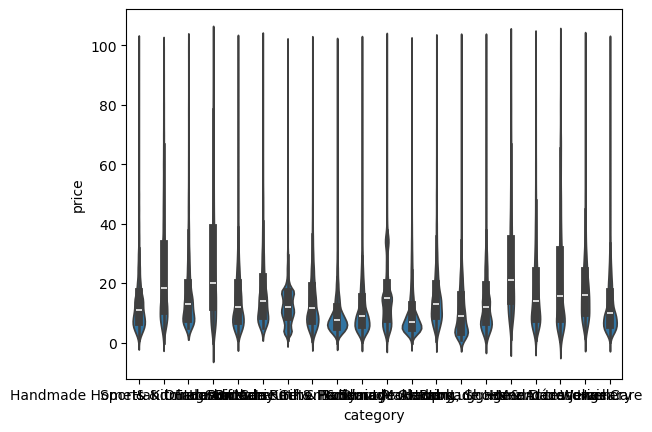

In [108]:
sns.violinplot(data=df_filtered[df_filtered["category"].isin(top20_cat)], x = "category", y = "price")
# this is what the exercise said, I'm going to reduce it more so we can see it

([0, 1, 2, 3, 4],
 [Text(0, 0, 'Sports & Outdoors'),
  Text(1, 0, 'Bath & Body'),
  Text(2, 0, 'Manicure & Pedicure Products'),
  Text(3, 0, 'Beauty'),
  Text(4, 0, 'Handmade Clothing, Shoes & Accessories')])

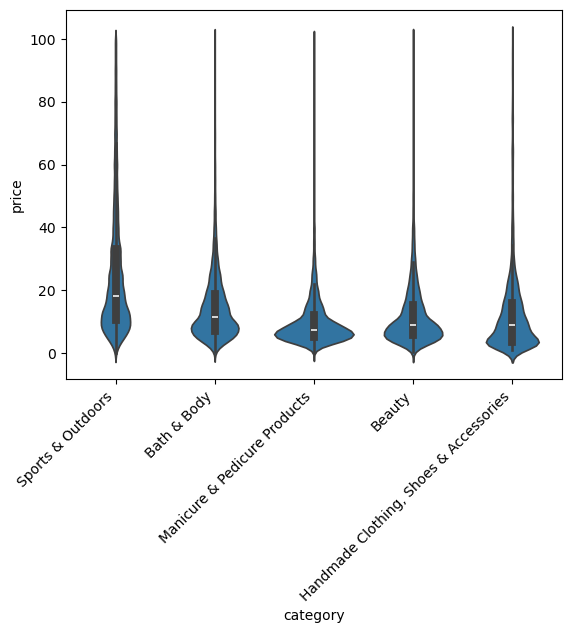

In [111]:
sns.violinplot(data=df_filtered[df_filtered["category"].isin(top5_cat)], x = "category", y = "price")
plt.xticks(rotation=45, ha="right")

In [119]:
df_filtered.groupby("category")["price"].median().sort_values(ascending = False).head()
#Desktop PCs have the higher median

category
Desktop PCs       74.00
Boxing Shoes      69.79
Tablets           69.00
Graphics Cards    68.54
Motherboards      67.92
Name: price, dtype: float64

In [121]:
top10_cat = df_filtered.value_counts("category").sort_values(ascending = False).head(10).index

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, 'Sports & Outdoors'),
  Text(1, 0, 'Handmade Gifts'),
  Text(2, 0, 'Skin Care'),
  Text(3, 0, 'Birthday Gifts'),
  Text(4, 0, 'Bath & Body'),
  Text(5, 0, 'Manicure & Pedicure Products'),
  Text(6, 0, 'Beauty'),
  Text(7, 0, 'Make-up'),
  Text(8, 0, 'Handmade Clothing, Shoes & Accessories'),
  Text(9, 0, 'Hair Care')])

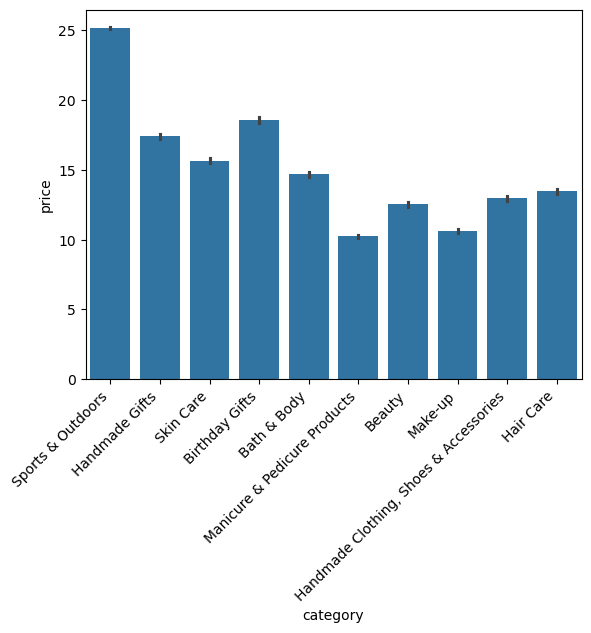

In [123]:
sns.barplot(data=df_filtered[df_filtered["category"].isin(top10_cat)], x = "category", y = "price")
plt.xticks(rotation=45, ha="right")

In [126]:
df_filtered.groupby("category")["price"].mean().sort_values(ascending= False)
# the motherboards have the highest mean price

category
Motherboards             68.772432
Boxing Shoes             67.417803
Desktop PCs              66.915562
Tablets                  66.552971
Graphics Cards           65.103509
                           ...    
Bedding Accessories       8.835220
Adapters                  8.750197
Signs & Plaques           8.210513
Arts & Crafts             8.006540
Office Paper Products     6.876369
Name: price, Length: 296, dtype: float64

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, 'Sports & Outdoors'),
  Text(1, 0, 'Handmade Gifts'),
  Text(2, 0, 'Skin Care'),
  Text(3, 0, 'Birthday Gifts'),
  Text(4, 0, 'Bath & Body'),
  Text(5, 0, 'Manicure & Pedicure Products'),
  Text(6, 0, 'Beauty'),
  Text(7, 0, 'Make-up'),
  Text(8, 0, 'Handmade Clothing, Shoes & Accessories'),
  Text(9, 0, 'Hair Care')])

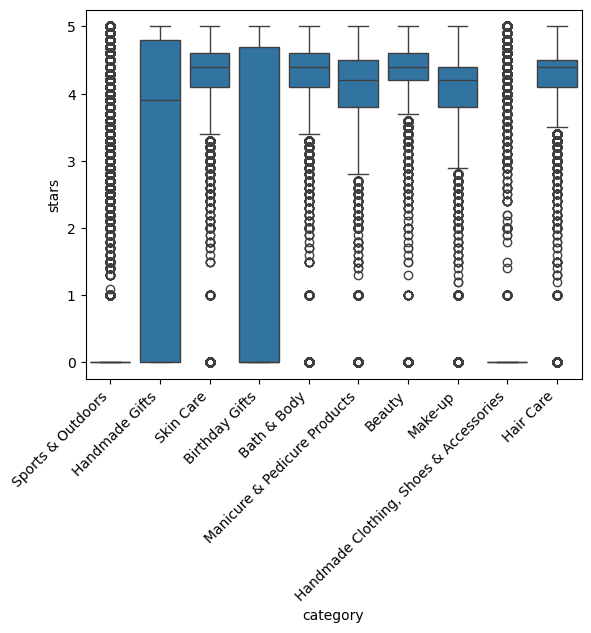

In [129]:
sns.boxplot(data = df_filtered[df_filtered["category"].isin(top10_cat)], x = "category", y = "stars")
plt.xticks(rotation=45, ha="right")

In [130]:
df_filtered.groupby("category")["stars"].median().sort_values(ascending = False).head()
# the highest median by category is computer memory with a 4.7

category
Computer Memory                 4.7
Building & Construction Toys    4.6
Office Paper Products           4.6
Luxury Food & Drink             4.6
Kids' Play Figures              4.6
Name: stars, dtype: float64

### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

1. **Correlation Coefficients**:
    
    - Calculate the correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating?
2. **Visualizations**:
    
    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    - Use a correlation heatmap to visualize correlations between all numerical variables.
    - Examine if product prices typically follow a normal distribution using a QQ plot.

In [134]:
print("Pearson Correlation: ", df_filtered["price"].corr(df_filtered["stars"]))
print("Spearman Correlation: ", df_filtered["price"].corr(df_filtered["stars"], method = "spearman"))
# there isn't a significant correlation between them. in fact, it is really weak

Pearson Correlation:  -0.0776729987818131
Spearman Correlation:  -0.06679697280768324


<Axes: xlabel='stars', ylabel='price'>

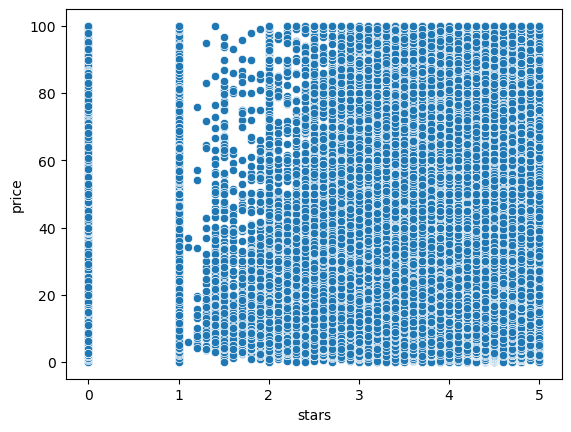

In [136]:
sns.scatterplot(data = df_filtered, x = "stars", y = "price")
# i can't obserbe any pattern. 

<Axes: >

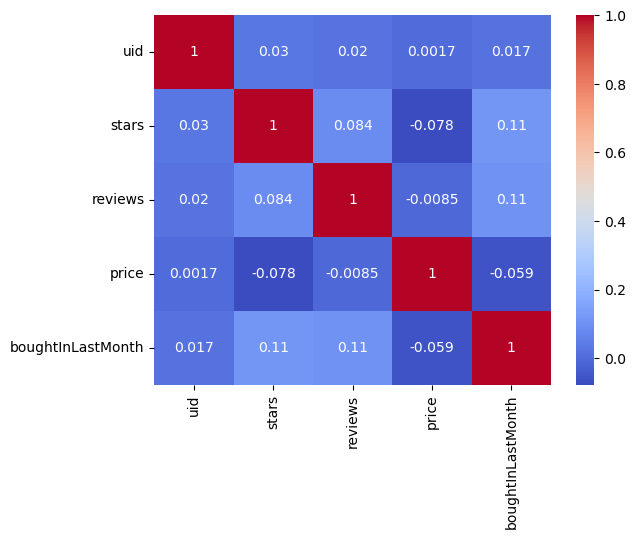

In [143]:
sns.heatmap(df_filtered.select_dtypes("number").corr(), annot= True, cmap = "coolwarm")